# Loading the Data

In [5]:
import os
import pandas as pd

DATASET_DIR = "UTKFace"

filenames = pd.Series(os.listdir(DATASET_DIR))
jpg_files = filenames[filenames.str.endswith(".jpg", na=False)]

# Reading the data

In [6]:
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

IMG_SIZE = (32, 32)
img_paths = DATASET_DIR + "/" + jpg_files

In [7]:
images_list = list(map(lambda p: img_to_array(load_img(p, target_size=IMG_SIZE)), img_paths))
images_list

[array([[[195., 186., 181.],
         [152., 143., 134.],
         [178., 170., 159.],
         ...,
         [134., 134., 136.],
         [ 98., 102., 103.],
         [ 95.,  98., 105.]],
 
        [[186., 177., 172.],
         [158., 149., 140.],
         [175., 167., 156.],
         ...,
         [120., 120., 120.],
         [133., 137., 136.],
         [ 99.,  99., 107.]],
 
        [[190., 181., 174.],
         [172., 164., 153.],
         [185., 177., 166.],
         ...,
         [121., 121., 119.],
         [117., 119., 116.],
         [103., 102., 110.]],
 
        ...,
 
        [[245., 244., 250.],
         [243., 242., 248.],
         [241., 240., 246.],
         ...,
         [108., 107., 115.],
         [107., 106., 114.],
         [103., 102., 108.]],
 
        [[244., 243., 249.],
         [238., 237., 243.],
         [236., 235., 241.],
         ...,
         [107., 106., 112.],
         [100.,  99., 105.],
         [ 99.,  98., 104.]],
 
        [[237., 236., 242.],
 

In [8]:
images = np.array(images_list, dtype="float32")
images

array([[[[195., 186., 181.],
         [152., 143., 134.],
         [178., 170., 159.],
         ...,
         [134., 134., 136.],
         [ 98., 102., 103.],
         [ 95.,  98., 105.]],

        [[186., 177., 172.],
         [158., 149., 140.],
         [175., 167., 156.],
         ...,
         [120., 120., 120.],
         [133., 137., 136.],
         [ 99.,  99., 107.]],

        [[190., 181., 174.],
         [172., 164., 153.],
         [185., 177., 166.],
         ...,
         [121., 121., 119.],
         [117., 119., 116.],
         [103., 102., 110.]],

        ...,

        [[245., 244., 250.],
         [243., 242., 248.],
         [241., 240., 246.],
         ...,
         [108., 107., 115.],
         [107., 106., 114.],
         [103., 102., 108.]],

        [[244., 243., 249.],
         [238., 237., 243.],
         [236., 235., 241.],
         ...,
         [107., 106., 112.],
         [100.,  99., 105.],
         [ 99.,  98., 104.]],

        [[237., 236., 242.],
       

In [9]:
ages_series = jpg_files.str.split("_").str[0].astype(float)
ages_series

0        100.0
1        100.0
2        100.0
3        100.0
4        100.0
         ...  
23703      9.0
23704      9.0
23705      9.0
23706      9.0
23707      9.0
Length: 23708, dtype: float64

In [10]:
ages = ages_series.to_numpy()
ages

array([100., 100., 100., ...,   9.,   9.,   9.], shape=(23708,))

# Preprocessing

In [11]:
import numpy as np

images = images / 255.0
images

array([[[[0.7647059 , 0.7294118 , 0.70980394],
         [0.59607846, 0.56078434, 0.5254902 ],
         [0.69803923, 0.6666667 , 0.62352943],
         ...,
         [0.5254902 , 0.5254902 , 0.53333336],
         [0.38431373, 0.4       , 0.40392157],
         [0.37254903, 0.38431373, 0.4117647 ]],

        [[0.7294118 , 0.69411767, 0.6745098 ],
         [0.61960787, 0.58431375, 0.54901963],
         [0.6862745 , 0.654902  , 0.6117647 ],
         ...,
         [0.47058824, 0.47058824, 0.47058824],
         [0.52156866, 0.5372549 , 0.53333336],
         [0.3882353 , 0.3882353 , 0.41960785]],

        [[0.74509805, 0.70980394, 0.68235296],
         [0.6745098 , 0.6431373 , 0.6       ],
         [0.7254902 , 0.69411767, 0.6509804 ],
         ...,
         [0.4745098 , 0.4745098 , 0.46666667],
         [0.45882353, 0.46666667, 0.45490196],
         [0.40392157, 0.4       , 0.43137255]],

        ...,

        [[0.9607843 , 0.95686275, 0.98039216],
         [0.9529412 , 0.9490196 , 0.972549  ]

In [13]:
labels = ages
labels

array([100., 100., 100., ...,   9.,   9.,   9.], shape=(23708,))

# Split Data

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(images, labels, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Model

In [15]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

In [20]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout

model = Sequential([
        Flatten(input_shape=(32, 32, 3)),
        Dense(256, activation='relu'),
        Dropout(0.3),
        Dense(128, activation='relu'),
        Dense(1, activation='linear')])


In [21]:
model.compile(optimizer='adam', 
    loss='mean_squared_error', 
    metrics=['mae'] )

In [22]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │         786,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 819,713 (3.13 MB)

 Trainable params: 819,713 (3.13 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32)

Epoch 1/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 211.6828 - mae: 10.7461 - val_loss: 212.5929 - val_mae: 10.6126
Epoch 2/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 208.7555 - mae: 10.7217 - val_loss: 204.5410 - val_mae: 10.5091
Epoch 3/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 213.6169 - mae: 10.7972 - val_loss: 207.7745 - val_mae: 10.6868
Epoch 4/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 212.8779 - mae: 10.8387 - val_loss: 183.4899 - val_mae: 9.8180
Epoch 5/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 206.4100 - mae: 10.6651 - val_loss: 183.8031 - val_mae: 10.0649
Epoch 6/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 204.2324 - mae: 10.6519 - val_loss: 202.3150 - val_mae: 10.9608
Epoch 7/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 203.8066 - mae: 10.6131 - val_loss: 247.3294 - val_mae: 12.0991
Epoch 8/50
519/519 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 196.3273 - mae: 10.4135 - val_loss: 208.4016 - val_mae: 10.7902
E

In [25]:
history_df = pd.DataFrame(history.history)

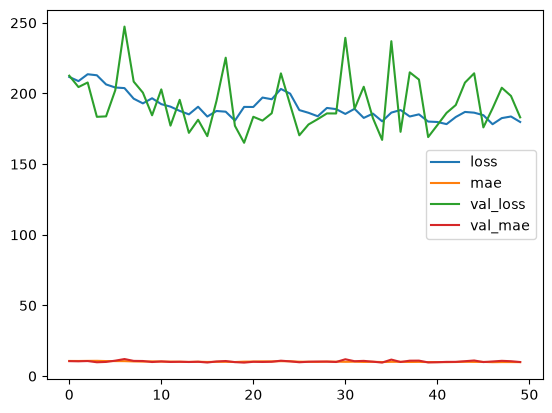

In [26]:
history_df.plot();

In [27]:
model.save("age_model.h5")